In [1]:
import torch
import matplotlib.pyplot as plt

from ngo.numericalanalysis.basisfunctions import *
from ngo.numericalanalysis.linalg import *
from ngo.trainingdata.GRF import *

In [2]:
# # Copyright 2025 Joost Prins
# """Gaussian Random Field (GRF) generator for training data.

# This module implements a Gaussian Random Field sampler using Kronecker-product
# structure for efficient generation of spatially correlated random fields in
# multiple dimensions.
# """

# # 3rd Party
# import torch

# #Local
# from ngo.numericalanalysis.linalg import kron_matvec, kron_solve_triangular


# class GRF:
#     """Gaussian Random Field generator with squared exponential covariance.
    
#     Generates random fields with spatial correlation determined by length scales.
#     Uses Kronecker-product structure to efficiently sample and compute the
#     conditional mean of the GRF given the samples. The random fields are interpolated
#     on a Gaussian Radial Basis Function (GRBF) basis on a regular grid.
    
#     The covariance kernel is a product of 1D squared exponential kernels:
#         K(x, x') = exp(-0.5 * sum_i ((x_i - x'_i) / l_i)^2)
    
#     Attributes:
#         device (torch.device): Device for tensor operations.
#         dtype (torch.dtype): Data type for tensors.
#         N_samples (int): Number of GRF samples to generate.
#         l (torch.Tensor): Length scales for each dimension, shape (d,).
#         l_Dx_ratio (int): Ratio determining grid resolution relative to length scales.
#         n (tuple): Grid sizes for each dimension. "n_i = ceil(1 / l_i) + 1".
#         mus (tuple): Grid points for each dimension, each element shape (n_i,).
#         f_m (torch.Tensor): Basis interpolation coefficient tensor, shape (N_samples, n_0, ..., n_{d-1}).
#         f (torch.Tensor): GRF samples, shape (N_samples, n_0, ..., n_{d-1}).
#     """
#     def __init__(self, N_samples, l, n, device, dtype):
#         """Initialize the GRF generator.
        
#         Parameters:
#             N_samples (int): Number of random field samples to generate.
#             l (tuple): Length scales for each spatial dimension. Tuple length
#                 determines the dimensionality of the random field.
#             device (torch.device or str): Device for computation ('cpu' or 'cuda').
#             dtype (torch.dtype): Data type for tensors (e.g., torch.float32).
#         """
#         super().__init__()
#         self.device = device
#         self.dtype = dtype
#         self.N_samples = N_samples
#         self.l = torch.tensor(l, device=self.device, dtype=dtype)
#         self.n = n  #Number of points in each dimension
#         if n==None:
#             self.l_Dx_ratio = 1
#             self.n = tuple((self.l_Dx_ratio*(1.0 / self.l).ceil().long() + 1).tolist())
#         self.mus = self.get_mus()
#         self.f_m = self.compute_coeffs()
    
#     def get_mus(self):
#         """Generate grid points for each dimension.
        
#         Creates uniform grids in [0, 1] for each spatial dimension with
#         resolution determined by the length scale and l_Dx_ratio.
        
#         Returns:
#             tuple: Grid points for each dimension, each element a 1D tensor
#                 of shape (n_i,).
#         """
#         mus = ()
#         for i in range(len(self.l)):
#             mus += (torch.linspace(0,1, self.n[i], device=self.device, dtype=self.dtype),)
#         return mus
    
#     def compute_covariances(self):
#         """Compute covariance matrices for each dimension.
        
#         Computes the 1D squared exponential covariance matrices that form
#         the Kronecker-product structure of the full covariance.
        
#         Returns:
#             tuple: Covariance matrices K_i, each with shape (n_i, n_i).
#         """
#         K_i = ()
#         for i in range(len(self.l)):
#             scaled_mus = self.mus[i] / self.l[i]
#             diff = scaled_mus[:, None] - scaled_mus[None, :]
#             dist_sq = diff**2
#             K_i += (torch.exp(-0.5 * dist_sq),)
#         return K_i
    
#     def compute_coeffs(self):
#         """Generate GRF samples and compute their conditional mean.
        
#         Uses Cholesky factorization of the Kronecker-product covariance to
#         generate samples, then interpolates the GRF data points f on a Gaussian
#         Radial Basis Function (GRBF) basis, by solving a sequence of 1D triangular systems.
        
#         Returns:
#             torch.Tensor: Conditional mean of the GRF samples, shape
#                 (N_samples, n_0, n_1, ..., n_{d-1}).
        
#         Notes:
#             - Stores the GRF samples in self.f
#             - The interpolation coefficients f_m satisfy:
#               (K_0 ⊗ K_1 ⊗ ... ⊗ K_{d-1}) @ f_m = f
#         """
#         K_i = self.compute_covariances()
#         L_i = tuple(torch.linalg.cholesky(K) for K in K_i)
#         # Sample standard normal variables
#         Z = torch.randn(size=(self.N_samples,*self.n), device=self.device, dtype=self.dtype)
#         # GRF generation
#         L_i_batch = tuple(L[None,:] for L in L_i)
#         self.f = kron_matvec(L_i_batch, Z)
#         # Forward solve
#         L_i_T = tuple(L.T for L in L_i)
#         y = kron_solve_triangular(L_i_T, self.f, upper=True, left=False)
#         #Backward solve
#         f_m = kron_solve_triangular(L_i, y, upper=False, left=False)
#         return f_m

In [3]:
torch.cuda.empty_cache()
l_min = 0.5
l_max = 1
# lambdas = torch.rand(100,1)*(l_max - l_min) + l_min
lambdas=(1,)
grf = GRF(N_samples=1, l=lambdas, n=None, device='cuda', dtype=torch.float64)

In [4]:
grf.f_m.shape

torch.Size([1, 2])

In [5]:
grf.f_m.shape

torch.Size([1, 2])

In [6]:
grf.mus[0].shape

torch.Size([2])

In [7]:
grf.l.shape

torch.Size([1])

In [8]:
grf.l[None,:].shape

torch.Size([1, 1])

In [9]:
basis_t = GaussianRBFBasis(lambdas=grf.l[None,:], mus=grf.mus[0])

In [10]:
t = torch.linspace(0,1,1000, device='cuda', dtype=torch.float64)
basis_t.forward(t).shape

torch.Size([1, 2, 1000])

In [11]:
grf.f_m.shape

torch.Size([1, 2])

In [12]:
grf.f.shape

torch.Size([1, 2])

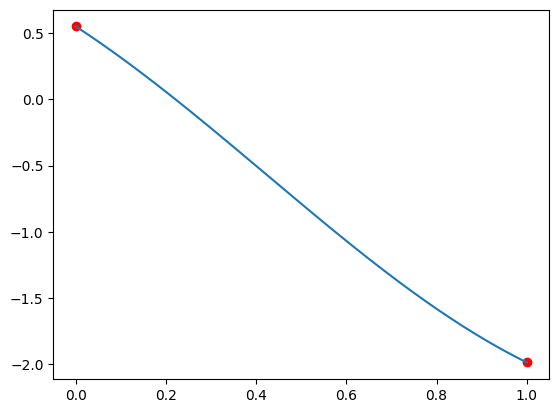

In [13]:
sample = 0
t = torch.linspace(0,1,1000, device='cuda', dtype=torch.float64)
y = torch.einsum('Nn,Nnx->Nx', grf.f_m, basis_t.forward(t))[sample]
plt.plot(t.cpu(), y.cpu())
plt.scatter(grf.mus[0].cpu(), grf.f[sample].cpu(), color='red')

In [14]:
torch.cuda.empty_cache()
lambdas = (0.05,0.05)
grf = GRF(N_samples=100, l=lambdas, n=None, device='cuda', dtype=torch.float64)

In [15]:
grf.f_m.shape

torch.Size([100, 21, 21])

In [16]:
grf.l.shape

torch.Size([2])

In [17]:
grf.l[None,0:1].shape

torch.Size([1, 1])

In [18]:
basis_t = GaussianRBFBasis(lambdas=grf.l[None,0:1], mus=grf.mus[0])
basis_x = GaussianRBFBasis(lambdas=grf.l[None,1:2], mus=grf.mus[1])

basis = TensorProductBasis((basis_t, basis_x))

In [19]:
t = torch.linspace(0,1,1000, device='cuda', dtype=torch.float64)
x = torch.linspace(0,1,1000, device='cuda', dtype=torch.float64)
X = (t,x)

In [20]:
basis.forward(grf.f_m, X).shape

/home/joostprins/git/ngo-pde-gk/src/ngo/numericalanalysis/basisfunctions.py:457: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Phi_i = torch.tensor(self.bases[i].forward(x[i]), device=u_m.device, dtype=u_m.dtype)


torch.Size([100, 1000, 1000])

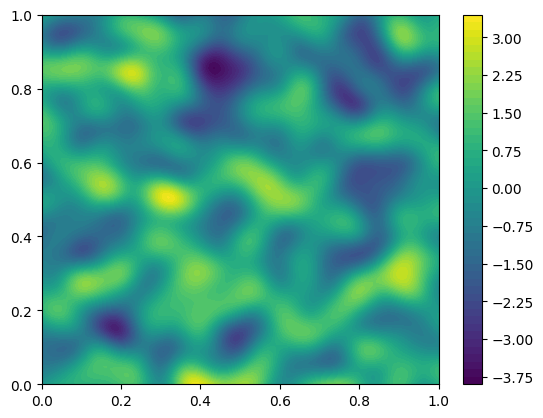

In [21]:
grid = torch.meshgrid(t.cpu(), x.cpu(), indexing='ij')
mus_grid = torch.meshgrid(grf.mus[0], grf.mus[1], indexing='ij')
plt.contourf(grid[1], grid[0], basis.forward(grf.f_m, X).cpu()[0], levels=50)
plt.colorbar()

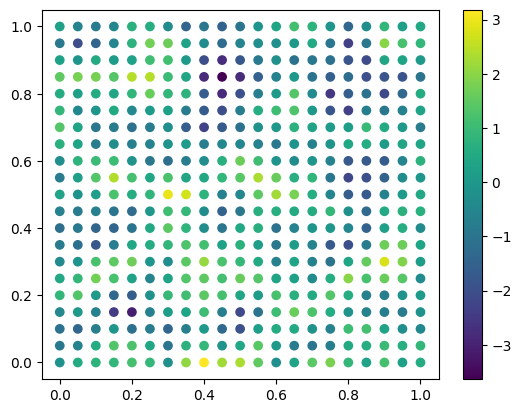

In [22]:
grid = torch.meshgrid(t.cpu(), x.cpu(), indexing='ij')
mus_grid = torch.meshgrid(grf.mus[0], grf.mus[1], indexing='ij')
plt.scatter(mus_grid[1].cpu(), mus_grid[0].cpu(), c=grf.f[0].cpu())
plt.colorbar()

In [24]:
torch.cuda.empty_cache()
l_min = 0.05
l_max = 1
lambdas = torch.rand(100,1, device='cuda', dtype=torch.float64)*(l_max - l_min) + l_min

f_m_set = torch.zeros((100,10), device='cuda', dtype=torch.float64)
f_set = torch.zeros((100,10), device='cuda', dtype=torch.float64)
for i in range(100):
    grf = GRF(N_samples=1, l=lambdas[i], n=(10,), device='cuda', dtype=torch.float64)
    f_m_set[i,:] = grf.f_m
    f_set[i,:] = grf.f

In [25]:
f_m_set.shape

torch.Size([100, 10])

In [26]:
basis_t = GaussianRBFBasis(lambdas=lambdas, mus=grf.mus[0])

In [27]:
t = torch.linspace(0,1,1000, device='cuda', dtype=torch.float64)
basis_t.forward(t).shape

torch.Size([100, 10, 1000])

In [28]:
f_interpolated = torch.einsum('Nn,Nnx->Nx', f_m_set, basis_t.forward(t))

tensor([0.1509], device='cuda:0', dtype=torch.float64)


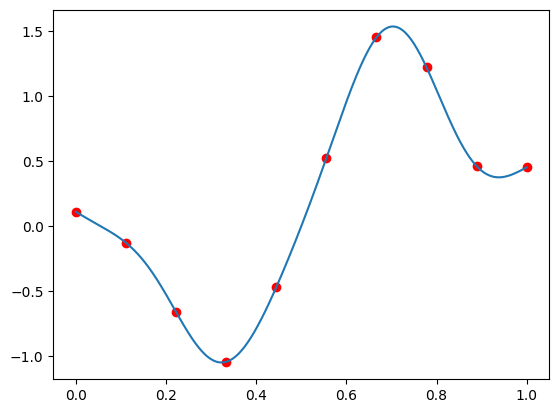

In [34]:
sample = 4
t = torch.linspace(0,1,1000, device='cuda', dtype=torch.float64)
plt.plot(t.cpu(), f_interpolated[sample].cpu())
plt.scatter(grf.mus[0].cpu(), f_set[sample].cpu(), color='red')
print(lambdas[sample])